# 9.RotorRigido
### Física Electrónica - UTN FRA
*Cuaderno interactivo adaptado para Google Colab.*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)


In [1]:
#@title
from google.colab import files
from IPython.display import Image
uploaded=files.upload()

Saving aa.png to aa.png
Saving abanico.png to abanico.png
Saving faa.png to faa.png
Saving rotor.png to rotor.png
Saving spherical.png to spherical.png


In [8]:
import scipy.special as sp
from numpy import *
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

def modY(l,m): 
    PHI=arange(0,2*pi,0.05)
    THETA=arange(0,pi,0.05)
    PHI, THETA=meshgrid(PHI,THETA)
    R = abs(sp.sph_harm(m, l, PHI, THETA))     #Array de valores absolutos de Ymn

    #A continuación convertimos a coordenadas cartesianas para su representación 3D

    X = R * sin(THETA) * cos(PHI)
    Y = R * sin(THETA) * sin(PHI)
    Z = R * cos(THETA)

    # Plot the surface

    fig, ax = plt.subplots(subplot_kw=dict(projection='3d'), figsize=(12,10))
    im = ax.plot_surface(X, Y, Z, rstride=1, cstride=1)

from __future__ import division
import scipy as sci
import scipy.special as sp
from numpy import *
import matplotlib
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm, colors

PHI, THETA = mgrid[0:2*pi:200j, 0:pi:100j] #arrays de variables angulares
def AE(x):    
    R = x
    #A continuación convertimos a coordenadas cartesianas
    # para su representación 3D
    X = R * sin(THETA) * cos(PHI)
    Y = R * sin(THETA) * sin(PHI)
    Z = R * cos(THETA)
    N = R/R.max()    # Normalizar R para que los colores del plot cubran todo el rango del colormap.
    fig, ax = plt.subplots(subplot_kw=dict(projection='3d'), figsize=(12,10))
    im = ax.plot_surface(X, Y, Z, rstride=1, cstride=1, facecolors=cm.jet(N))
    m = cm.ScalarMappable(cmap=cm.jet)
    m.set_array(R)

# **Rotor rígido**

La rotación de una molecula diatómica puede describirse por medio del rotor rígido. El rotor consiste de dos masas puntuales $m_1$ y $m_2$ cuyas distancias fijas a su centro de masas son son $l_1$ y $l_2$, como se muestra en la siguiente figura:  

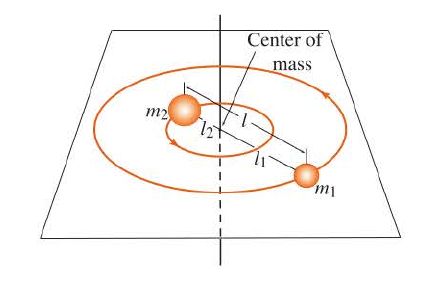

In [3]:
#@title
Image(filename='rotor.png', width=500, height=320)
# Figura tomada de: McQuarrie D., Quantum Chemistry, Viva Books, 2016.

Aunque una molécula diatómica vibre y rote, considerar un modelo en el que la longitud de enlace es fija proporciona un aproximación razonable al movimiento rotacional de la molécula, puesto que la amplitud vibracional es pequeña con respecto a la longitud de enlace. Si $\nu$ es la frecuencia rotacional de la molécula alrededor de su centro de masas, las velocidades $v_1$ y $v_2$ alrededor del centro de masas son $v_1=2\pi\nu l_1=l_1\omega$ y $v_2=2\pi\nu l_2=l_2\omega$. Por lo tanto la energía cinética del rotor rígido esta dada por:

$$K=\frac{1}{2}m_1v_1^2+\frac{1}{2}m_2v_2^2=\frac{1}{2}m_1l_1^2\omega^2+\frac{1}{2}m_2l_2^2\omega^2=\frac{1}{2}(m_1l_1^2+m_2l_2^2)\omega^2=\frac{1}{2}I\omega^2$$

donde $I=m_1l_1^2+m_2l_2^2$ es el momento de inercia de la molécula. Teniendo en cuenta que el centro de masas de la molécula satisface la ecuación $m_1l_1=m_2l_2$, el momento de inercia del sistema se puede escribir de la forma $I=\mu l^2$, donde $\mu=\frac{m_1m_2}{m_1+m_2}$ (masa reducida) y $l=l_1+l_2$. Note que esta ecuación es similar a la ecuación del momemto de inercia de una masa puntual $m$ que gira alrededor de un centro fijo del cual dista $l$ unidades, es decir $I=ml^2$. Por lo tanto podemos describir el movimiento rotacional de una molécula a través del movimiento rotacional de un objeto puntual de masa $\mu$ que gira alrededor de un centro fijo del cual dista $l$ unidades, y para el cual su momento de inercia, momento angular y energía cinética están dados respectivamente por

$$I=\mu l^2 \quad  \quad  \quad  \quad L=I\omega \quad  \quad y \quad  \quad  K=\frac{L^2}{2I} $$

Para este sistema el operador de energía total ($Hamiltoniano$) depende solamente de la energía cinética, ya que en ausencia de fuerzas externas la energía de la molécula no depende de su orientación en el espacio.

$$\hat{H}=\hat{K}=-\frac{\hbar^2}{2\mu}(\frac{\partial^2}{\partial x^2},\frac{\partial^2}{\partial y^2},\frac{\partial^2}{\partial z^2})=-\frac{\hbar^2}{2\mu}\nabla^2$$

Teniendo en cuenta que el sistema tiene un centro de simétria a distancia constante el Hamiltoniano se escribira en coordenadas esféricas

$$\hat{H}=-\frac{\hbar^2}{2I}[\frac{1}{sin\theta}\frac{\partial}{\partial\theta}(sin\theta\frac{\partial}{\partial\theta})+\frac{1}{sin^2\theta}(\frac{\partial^2}{\partial\phi^2})]$$

Como la distancia al centro de simetría es fija la dirección del rotor rígido esta completamente específicado por los ángulos $\theta$ y $\phi$. Donde $\phi$ es el ángulo medido desde el eje $x$ sobre el plano $xy$ en la dirección contraria a las manecillas del reloj ($0\leq \phi \leq 2\pi$) y $\theta$ es el ángulo medido de norte a sur desde la parte positiva del eje $z$ ($0\leq \theta \leq \pi$). En la siguiente figura se pueden observar estas orientaciones

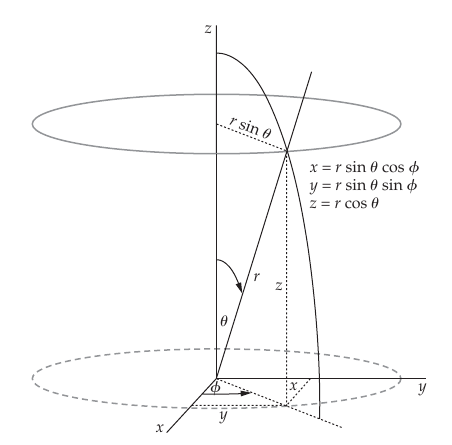

In [4]:
#@title
Image(filename='spherical.png', width=500, height=400)
# Figura tomada de: Tipler P., Mosca G., Physics for Scientists and Engineers, Freeman and Company, 2008.

Las funciones de onda del rotor rígido se suelen denotar por $Y(\theta,\phi)$ y por lo tanto la ecuación de Schrödinger para este sistema es $\hat{H}Y(\theta,\phi)=EY(\theta,\phi)$. Su solución se específica a continuación

$$\hat{H}Y(\theta,\phi)=\frac{\hbar^2}{2I}l(l+1)Y(\theta,\phi)$$

donde $Y(\theta,\phi)=Y_{l,m_l}(\theta,\phi)$ es 

$$Y_{l,m_l}(\theta,\phi)=[\frac{(2l+1)}{4\pi}\frac{(l-|m_l|)!}{(l+|m_l|)!}]^{1/2}P_l^{|m_l|}(cos\theta)e^{im_l\phi}$$

donde $l=0,1,2,3,...$ y $m_l=0,\pm 1, \pm 2, \pm 3,...\pm l$. En la última expresión $P_l^{|m_l|}(x)$ representa las funciones de Legendre asociadas evaluadas en $x=\cos\theta$, las cuales están dadas por la expresión

$$P_l^{|m_l|}(x)=(1-x^2)^{|m_l|/2}\frac{d^{|m_l|}}{dx^{|m_l|}}P_l(x)$$

donde $P_l(x)$ simboliza los polinomios de Legendre, los cuales están definidos por $P_l(x)=\frac{1}{2^nn!}\frac{d^n}{dx^n}[(x^2-1)^]$. Las funciones $Y_{l,m_l}(\theta,\phi)$ se conocen como $\textbf{armónicos esféricos}$. 

Como podemos ver los valores de energía total del rotor rígido dependen del $\textbf{número cuántico de momento angular l}$ y están confinados a los valores 

$$E_l=\frac{\hbar^2}{2I}l(l+1), \ \ \ \ l=0,1,2,3,...$$

## Problema 1

Encuentre los valores de energía para un rotor rígido, cuando:

1. $l=0$
2. $l=1$
3. $l=3$
4. $l=10$
5. $l=100$

¿Qué puede concluir al respecto?

La forma algebraica de los armónicos esféricos se muestra en la siguiente tabla.

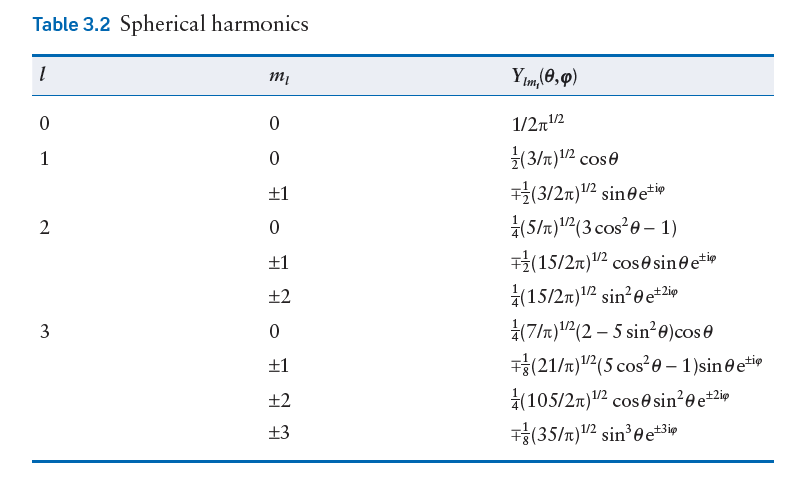

In [5]:
#@title
Image(filename='aa.png', width=700, height=400)
# Figura tomada de: Atkins P., Friedman R., Molecular Quantum Mechanics, Oxford, 2011.

## Problema 2

¿Para que valores de $l$ y $m_l$ los armónicos esféricos asumen valores complejos?

Como estas son funciones complejas, para su representación utilizaremos su módulo $| Y_{l,m_l}(\theta,\phi)|$ que es una función real. La función
$modY(l,m)$ realiza la representación gráfica de $| Y_{l,m_l}(\theta,\phi)|$.

## Ejercicio 1

En la celda inferior utilice la función $modY(l,m)$ para diferentes valores de $m$ y $l$. ¿Cuál es el significado probabilístico de estas funciones en el caso del rotor rígido?

In [ ]:
# Como podemos ver el espacio dos dimensional para el rotor rígido es la esfera con radio constante $r$ y la cantidad $|Y_{l,m_l}(\theta,\phi)|^2d\theta d\phi$
# representará la probabilidad de encontar el eje del rotor entre los ángulos $\theta+d\theta$ y $\phi+d\phi$. 

Los armónicos esféricos $Y_{l,m_l}(\theta,\phi)$
también son funciones propias de los operadores $\hat{L}^2$ y $\hat{L}_z$:


$$\hat{L}^2Y_{l,m_l}(\theta,\phi)=\hbar^2 l(l+1)Y_{l,m_l}(\theta,\phi),  \ \ \ \ l=0,1,2,3,...$$
$$\hat{L}_zY_{l,m_l}(\theta,\phi)=m_l\hbar Y_{l,m_l}(\theta,\phi),  \ \ \ \   m_l=0,\pm 1, \pm 2, \pm 3,...\pm l$$

La segunda ecuación nos muestran que el número cuántico $m_l$ específica la componente del momento angular a lo largo del eje $z$. Sin embargo los valores de $m_l$ están restringidos a ciertos valores, la componente $z$ del momento angular está restringida a $2l+1$ valores discretos. Está restricción se conoce como la $\textbf{cuantización de espacio}$. El nombre viene de la representación vectorial del momento angular, en la que el módulo del momento angular es $\hbar\sqrt{l(l+1)}$ y su proyección sobre el eje $z$ es $m_l\hbar$. Por lo tanto, el ángulo del vector momento angular con respecto al eje $z$ estará dado por

$$cos\theta=\frac{m_l}{\sqrt{l(l+1)}}$$

Este vector puede adoptar $2l+1$ orientaciones, como podemos ver en la siguiente figura para $l=2$, en contraste con la descripción clásica en la que la orientación de un cuerpo en rotación varia continuamente en el espacio.

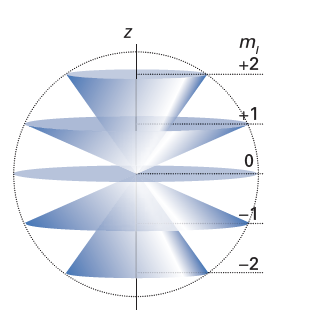

In [6]:
#@title
Image(filename='abanico.png', width=400, height=400)
# Figura tomada de: Atkins P., Friedman R., Molecular Quantum Mechanics, Oxford, 2011.

Como pudiste concluir antes los armónicos esféricos son funciones complejas, excepto para $m_l=0$, por lo tanto es costumbre utilizar combinaciones lineales de estos para obtener funciones reales que generen un conjunto ortonormal. La siguiente figura muestra esta combinación de armónicos esféricos.

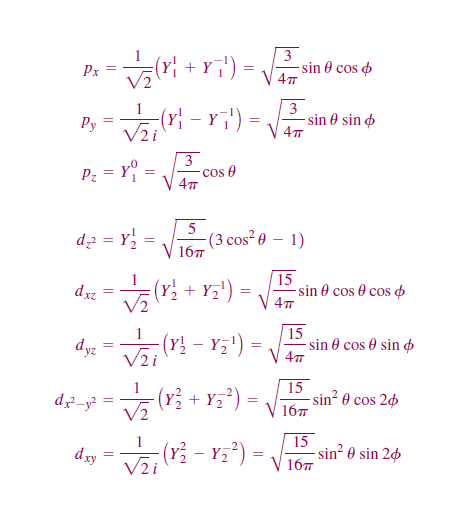

In [7]:
Image(filename='faa.png', width=500, height=550)
# Figura tomada de: Engel T., Quantum Chemistry and Spectroscopy, Pearson, 1996.

La función $AE(x)$ nos da una representación gráfica de las funciones anteriores. Para utilizar está función su argumento $x$ debe remplazarce por la función correspondiente. En la siguiente celda puedes ver un ejemplo. 

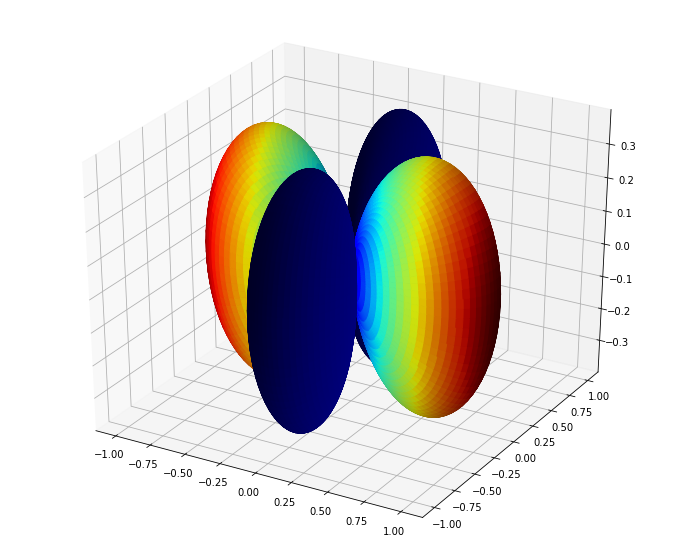

In [9]:
AE((sin(THETA))**2*cos(2*PHI))

## Ejercicio 2

Utilice la función $AE(x)$ para representar las funciones de onda encontradas como combinación de los armónicos esféricos. ¿Qué puede concluir al respecto? 

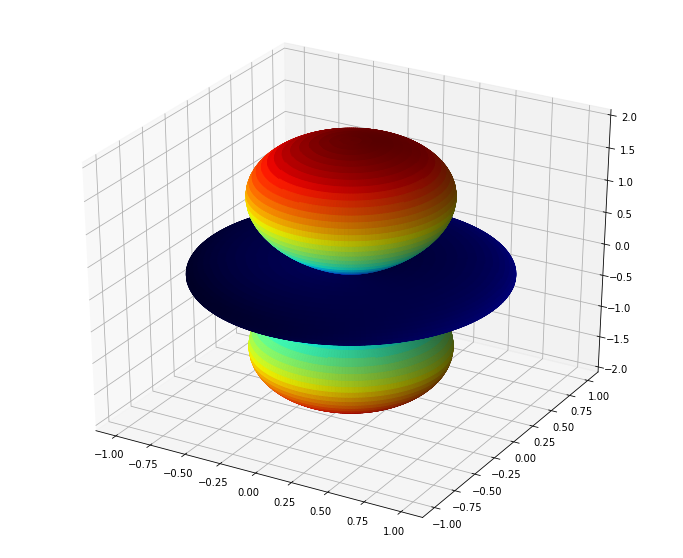

In [10]:
AE(3*cos(THETA)**2-1)

# Bibliografía

Atkins P. y Friedman R., Molecular Quantum Mechanics, Oxford, 2005.

Engel T., Quantum Chemistry and Spectroscopy, Pearson, 1996.